# 05 — Success and Star-Power Analysis

This notebook connects the semantic network outputs to movie success outcomes.

## Main question

Do narrative-network features and community membership relate to movie success outcomes, after accounting for year, genre, and simple cast/star-power proxies?

## Inputs

- `processed/network/semantic_network_nodes_lcc.csv`
- `outputs/tables/community_manual_labeling_template_labeled.csv`
- optionally `processed/core/df_thesis_films.csv`

## Outputs

- `processed/features/modeling_table_success_star_power.csv`
- `outputs/tables/modeling_sample_audit.csv`
- `outputs/tables/network_success_correlations.csv`
- `outputs/tables/community_success_summary.csv`
- `outputs/tables/regression_results_log_revenue.csv`
- `outputs/tables/regression_results_revenue_percentile.csv`
- `outputs/tables/regression_results_vote_average.csv`
- `outputs/tables/regression_results_popularity.csv`
- `outputs/figures/`

## Important interpretation rule

This notebook is **association analysis**, not causal proof.

The thesis-safe wording is:

> Network-derived narrative features are associated with success outcomes.

Not:

> Network features cause success.


## 1. Imports

In [1]:
import os
import re
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)

print("Imports ready.")

Imports ready.


## 2. Project paths

Set `PROJECT_DIR` to the root project folder.  
Do **not** point it to `processed/core` or `outputs/tables`.


In [2]:
from pathlib import Path

# Mount Drive only if it is not already mounted
try:
    from google.colab import drive

    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
OUTPUT_FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

for d in [PROCESSED_FEATURES_DIR, OUTPUT_TABLES_DIR, OUTPUT_FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

NODES_FILE = PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv"
LABELS_FILE = OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv"
THESIS_FILMS_FILE = PROCESSED_CORE_DIR / "df_thesis_films.csv"

MODELING_TABLE_OUT = PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv"

print("PROJECT_DIR:", PROJECT_DIR)
print("NODES_FILE exists?", NODES_FILE.exists())
print("LABELS_FILE exists?", LABELS_FILE.exists())
print("THESIS_FILMS_FILE exists?", THESIS_FILMS_FILE.exists())

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
NODES_FILE exists? True
LABELS_FILE exists? True
THESIS_FILMS_FILE exists? True


## 3. Load data

In [3]:
required = {
    "nodes": NODES_FILE,
    "labels": LABELS_FILE,
}

missing = [name for name, path in required.items() if not path.exists()]

if missing:
    for name in missing:
        print("Missing:", name, required[name])
    raise FileNotFoundError("Missing required inputs. Run Notebooks 3 and 4 first.")

nodes = pd.read_csv(NODES_FILE)
labels = pd.read_csv(LABELS_FILE)

print("nodes:", nodes.shape)
print("labels:", labels.shape)

display(nodes.head(3))
display(labels.head(3))

nodes: (19202, 30)
labels: (23, 15)


,node_id,tmdb_id,imdb_id,title,release_year,primary_genre,genres_clean,overview_word_count,runtime,popularity,vote_average,vote_count,revenue_clean,log_revenue,cast_clean,director_name,community_id,degree,weighted_degree,degree_centrality,eigenvector_centrality,pagerank,betweenness_centrality_sampled,clustering_coefficient,degree_rank,weighted_degree_rank,degree_centrality_rank,eigenvector_centrality_rank,pagerank_rank,betweenness_centrality_sampled_rank
0,0,11232,tt0035423,Kate & Leopold,2001,Romance,"Romance, Comedy, Fantasy",64,118.0,3.9819,6.3,1468.0,76019048.0,18.146495,"Del Pentecost, Andrea Barnes, Philip Bosco, Breckin Meyer, Robert Ray Manning Jr.",James Mangold,11,15,7.921253,0.000781,3.326597e-06,0.000077,0.000700,0.051451,2284,2832,2284,5585,2621,855
1,1,299782,tt0069049,The Other Side of the Wind,2018,Drama,Drama,36,122.0,1.5325,6.7,230.0,NaN,NaN,"Cybill Shepherd, Curtis Harrington, Eric Sherman, Louis Race, Stafford Repp",Orson Welles,5,14,6.916580,0.000729,9.714745e-07,0.000085,0.000673,0.053100,3043,4199,3043,10945,1190,987
2,2,23508,tt0082328,Embodiment of Evil,2008,Horror,"Horror, Thriller",59,94.0,2.5073,5.1,42.0,NaN,NaN,"Alessandra Miranda, Elder Fraga, José Celso Martinez Corrêa, Freak Garcia, André Frateschi",José Mojica Marins,22,9,4.450629,0.000469,1.858977e-06,0.000050,0.000269,0.000000,8334,9222,8334,8082,10086,6105


,interpretation_priority,community_id,n_films,share_of_network_pct,top_primary_genres,year_range,median_year,median_vote_count,median_vote_average,revenue_available_pct,central_titles_weighted_degree,bridging_titles_betweenness,visible_titles_vote_count,suggested_label_manual,interpretation_note_manual
0,1,14,1792,9.33,Drama (588); Comedy (389); Horror (209); Thriller (126); Action (116); Romance (104),1990-2024,2014.0,82.0,6.1,36.38,The House (2024); The Kindred (2021); Pistas para volver a casa (2015); Beyond the Law (2019); The Boogeyman (2023);...,Jungle (2017); The Covenant (2006); Imagining Argentina (2003); Rio (2011); Celebrity (1998); I Don't Kiss (1991),Forrest Gump (1994); The Hunger Games (2012); Spirited Away (2001); Man of Steel (2013); Her (2013); Avatar: The Way...,"Broad personal drama, family disruption, and domestic threat","This large community appears to collect broad character- and family-centered plots, often with domestic threat, grie..."
1,2,22,1735,9.04,Drama (632); Comedy (580); Romance (93); Horror (73); Thriller (72); Action (71),1990-2024,2014.0,79.0,6.3,32.16,"Amer (2009); Something New (2016); Mayday (2021); Sexo, Amor e Traição (2004); María (and Everybody Else) (2016); Da...",The Bandit (1996); Darkland (2017); Descent Into Darkness (2013); (Im)perfetti Criminali (2022); Quasimodo d'el Pari...,Coco (2017); The Incredibles (2004); La La Land (2016); Call Me by Your Name (2017); Fifty Shades of Grey (2015); Pa...,"Relationship drama, romantic comedy, and emotional-family crossover","This community seems to group relationship-centered and emotionally expressive narratives, especially romance, famil..."
2,3,12,1517,7.90,Drama (446); Comedy (275); Action (244); Animation (153); Romance (84); Horror (63),1990-2024,2013.0,61.0,6.6,34.15,Demon Slayer: Kimetsu no Yaiba - Sibling's Bond (2019); Samurai Cop (1991); Agitator (2001); Kabei: Our Mother (2008...,"Mommy, I'm Scared (2006); Under Construction (2003); Man Push Cart (2006); Apartment 1303 (2007); Amaran (2024); Yok...",Finding Nemo (2003); Your Name. (2016); Alita: Battle Angel (2019); Pretty Woman (1990); Princess Mononoke (1997); T...,Japanese/Korean action-animation and cross-cultural personal drama,"This neighborhood is strongly shaped by Japanese and Korean titles, anime-linked stories, and action-drama plots wit..."


## 4. Prepare community labels

The labeled community table is merged into the node table.

The graph still uses numeric `community_id`; the manual label is used for interpretation and grouped summaries.


In [4]:
label_cols = [
    "community_id",
    "suggested_label_manual",
    "interpretation_note_manual"
]

missing_label_cols = [c for c in label_cols if c not in labels.columns]
if missing_label_cols:
    raise ValueError(f"Missing label columns: {missing_label_cols}")

labels_small = labels[label_cols].drop_duplicates("community_id").copy()

df = nodes.merge(
    labels_small,
    on="community_id",
    how="left"
)

# Minor communities may not be manually labeled. Fill them safely.
df["suggested_label_manual"] = df["suggested_label_manual"].fillna("Minor / unlabeled community")
df["interpretation_note_manual"] = df["interpretation_note_manual"].fillna("Minor community not manually labeled.")

print("Merged modeling base:", df.shape)
print("Missing labels after merge:", df["suggested_label_manual"].isna().sum())

display(df[["title", "release_year", "community_id", "suggested_label_manual"]].head())

Merged modeling base: (19202, 32)
Missing labels after merge: 0


,title,release_year,community_id,suggested_label_manual
0,Kate & Leopold,2001,11,"Science-fiction, infection, dystopia, and altered-reality narratives"
1,The Other Side of the Wind,2018,5,"Music, creativity, celebrity, and artistic-life drama-comedy"
2,Embodiment of Evil,2008,22,"Relationship drama, romantic comedy, and emotional-family crossover"
3,Looney Tunes Spotlight Collection: The Premiere Edition,2004,5,"Music, creativity, celebrity, and artistic-life drama-comedy"
4,Halfaouine: Boy of the Terraces,1990,12,Japanese/Korean action-animation and cross-cultural personal drama


## 5. Clean numeric fields and create success outcomes

Success variables:

- `log_revenue`: already available where revenue is reported
- `revenue_percentile_year`: revenue percentile within release year
- `high_revenue_year`: top 25% revenue within release year
- `vote_average`: critical/audience rating proxy
- `popularity`: platform popularity proxy

Revenue analysis is only conducted on rows with available revenue.


In [5]:
# Ensure numeric columns
numeric_cols = [
    "release_year", "runtime", "popularity", "vote_average", "vote_count",
    "revenue_clean", "log_revenue",
    "degree", "weighted_degree", "degree_centrality",
    "eigenvector_centrality", "pagerank",
    "betweenness_centrality_sampled", "clustering_coefficient"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Create log revenue if missing
if "log_revenue" not in df.columns or df["log_revenue"].isna().all():
    df["log_revenue"] = np.where(
        df["revenue_clean"].fillna(0) > 0,
        np.log1p(df["revenue_clean"]),
        np.nan
    )

# Revenue percentile within year
df["revenue_percentile_year"] = np.nan

revenue_mask = df["revenue_clean"].notna() & (df["revenue_clean"] > 0) & df["release_year"].notna()

df.loc[revenue_mask, "revenue_percentile_year"] = (
    df.loc[revenue_mask]
    .groupby("release_year")["revenue_clean"]
    .rank(pct=True)
)

df["high_revenue_year"] = np.where(
    df["revenue_percentile_year"].notna(),
    (df["revenue_percentile_year"] >= 0.75).astype(int),
    np.nan
)

# Popularity transform
df["log_popularity"] = np.where(
    df["popularity"].fillna(0) > 0,
    np.log1p(df["popularity"]),
    np.nan
)

print("Revenue available:", df["revenue_clean"].notna().sum())
print("Revenue percentile available:", df["revenue_percentile_year"].notna().sum())

display(df[["title", "release_year", "revenue_clean", "log_revenue", "revenue_percentile_year", "high_revenue_year"]].head(10))

Revenue available: 7576
Revenue percentile available: 7576


,title,release_year,revenue_clean,log_revenue,revenue_percentile_year,high_revenue_year
0,Kate & Leopold,2001,76019048.0,18.146495,0.729282,0.0
1,The Other Side of the Wind,2018,NaN,NaN,NaN,NaN
2,Embodiment of Evil,2008,NaN,NaN,NaN,NaN
3,Looney Tunes Spotlight Collection: The Premiere Edition,2004,NaN,NaN,NaN,NaN
4,Halfaouine: Boy of the Terraces,1990,NaN,NaN,NaN,NaN
5,Demonia,1990,NaN,NaN,NaN,NaN
6,The Miser,1990,NaN,NaN,NaN,NaN
7,Baby Blood,1990,NaN,NaN,NaN,NaN
8,A Tale of Springtime,1990,NaN,NaN,NaN,NaN
9,Déjà vu,1990,NaN,NaN,NaN,NaN


## 6. Cast/star-power proxy

This creates practical cast proxies from `cast_clean`.

Proxy logic:

1. `cast_size`: number of listed cast members.
2. `top_cast_exposure_sum`: sum of actor exposure counts for the first few cast members.
3. `top_cast_exposure_max`: maximum actor exposure count among first few cast members.
4. `top_cast_exposure_mean`: average exposure count among first few cast members.
5. `has_high_exposure_actor`: whether a film has at least one actor in the top 10% of exposure.

This is not true historical star power. It is a dataset-based cast exposure proxy and should be explained cautiously.


In [6]:
def parse_cast_list(x):
    if pd.isna(x):
        return []

    s = str(x).strip()
    if s == "" or s.lower() in ["nan", "none", "[]"]:
        return []

    # Try common separators
    if "|" in s:
        parts = s.split("|")
    elif ";" in s:
        parts = s.split(";")
    elif "," in s:
        parts = s.split(",")
    else:
        parts = [s]

    clean = []
    for p in parts:
        p = str(p).strip()
        p = re.sub(r"\s+", " ", p)
        if p and p.lower() not in ["nan", "none", "unknown"]:
            clean.append(p)
    return clean

if "cast_clean" not in df.columns:
    df["cast_clean"] = ""

df["cast_list"] = df["cast_clean"].apply(parse_cast_list)
df["cast_size"] = df["cast_list"].apply(len)
df["has_cast"] = (df["cast_size"] > 0).astype(int)

# Use first N listed cast members as top-billed cast
TOP_CAST_N = 5
df["top_cast_list"] = df["cast_list"].apply(lambda x: x[:TOP_CAST_N])

# Actor exposure counts across the network sample
actor_counts = {}

for cast in df["top_cast_list"]:
    for actor in cast:
        actor_counts[actor] = actor_counts.get(actor, 0) + 1

actor_exposure = pd.Series(actor_counts, name="actor_exposure_count").sort_values(ascending=False)

if len(actor_exposure) > 0:
    high_exposure_threshold = actor_exposure.quantile(0.90)
else:
    high_exposure_threshold = np.nan

def actor_exposure_features(cast):
    exposures = [actor_counts.get(a, 0) for a in cast]

    if len(exposures) == 0:
        return pd.Series({
            "top_cast_exposure_sum": 0,
            "top_cast_exposure_max": 0,
            "top_cast_exposure_mean": 0,
            "has_high_exposure_actor": 0
        })

    return pd.Series({
        "top_cast_exposure_sum": float(np.sum(exposures)),
        "top_cast_exposure_max": float(np.max(exposures)),
        "top_cast_exposure_mean": float(np.mean(exposures)),
        "has_high_exposure_actor": int(np.max(exposures) >= high_exposure_threshold)
    })

exposure_features = df["top_cast_list"].apply(actor_exposure_features)
df = pd.concat([df, exposure_features], axis=1)

actor_exposure_table = actor_exposure.reset_index()
actor_exposure_table.columns = ["actor_name", "actor_exposure_count"]
actor_exposure_table.to_csv(OUTPUT_TABLES_DIR / "actor_exposure_counts.csv", index=False)

print("Actor exposure table:", actor_exposure_table.shape)
print("High exposure threshold:", high_exposure_threshold)

display(df[[
    "title", "cast_size", "top_cast_exposure_sum",
    "top_cast_exposure_max", "top_cast_exposure_mean",
    "has_high_exposure_actor"
]].head(10))

display(actor_exposure_table.head(20))

Actor exposure table: (68189, 2)
High exposure threshold: 2.0


,title,cast_size,top_cast_exposure_sum,top_cast_exposure_max,top_cast_exposure_mean,has_high_exposure_actor
0,Kate & Leopold,5,15.0,7.0,3.0,1.0
1,The Other Side of the Wind,5,6.0,2.0,1.2,1.0
2,Embodiment of Evil,5,5.0,1.0,1.0,0.0
3,Looney Tunes Spotlight Collection: The Premiere Edition,0,0.0,0.0,0.0,0.0
4,Halfaouine: Boy of the Terraces,5,6.0,2.0,1.2,1.0
5,Demonia,5,5.0,1.0,1.0,0.0
6,The Miser,5,6.0,2.0,1.2,1.0
7,Baby Blood,5,6.0,2.0,1.2,1.0
8,A Tale of Springtime,5,5.0,1.0,1.0,0.0
9,Déjà vu,5,5.0,1.0,1.0,0.0


,actor_name,actor_exposure_count
0,Brien,36
1,Connor,28
2,Neill,26
3,Donnell,26
4,Koichi Yamadera,23
5,Frank Welker,21
6,Tress MacNeille,20
7,Hara,20
8,Jeff Bennett,20
9,Takahiro Sakurai,19


## 7. Network feature transforms

Centrality variables are skewed, so we create log and standardized versions.

The raw variables remain available.


In [7]:
network_metrics = [
    "degree",
    "weighted_degree",
    "pagerank",
    "betweenness_centrality_sampled",
    "eigenvector_centrality",
    "clustering_coefficient"
]

for col in network_metrics:
    if col not in df.columns:
        raise ValueError(f"Missing network metric: {col}")

# Log transforms for positive/skewed metrics
for col in ["degree", "weighted_degree", "pagerank", "betweenness_centrality_sampled", "eigenvector_centrality"]:
    df[f"log_{col}"] = np.log1p(df[col].fillna(0))

# Standardized z-scores
z_cols = [
    "degree", "weighted_degree", "pagerank",
    "betweenness_centrality_sampled", "eigenvector_centrality",
    "clustering_coefficient",
    "cast_size", "top_cast_exposure_sum",
    "top_cast_exposure_max", "top_cast_exposure_mean"
]

for col in z_cols:
    mean = df[col].mean(skipna=True)
    std = df[col].std(skipna=True)
    if std and not np.isnan(std):
        df[f"z_{col}"] = (df[col] - mean) / std
    else:
        df[f"z_{col}"] = np.nan

print("Network/cast transforms created.")
display(df[[c for c in df.columns if c.startswith("z_")]].head())

Network/cast transforms created.


,z_degree,z_weighted_degree,z_pagerank,z_betweenness_centrality_sampled,z_eigenvector_centrality,z_clustering_coefficient,z_cast_size,z_top_cast_exposure_sum,z_top_cast_exposure_max,z_top_cast_exposure_mean
0,1.230390,1.162120,1.195289,2.077986,-0.039200,-0.130471,-0.066067,0.657463,0.622948,0.545365
1,1.024338,0.799666,1.614452,1.959474,-0.039527,-0.108345,-0.066067,-0.730585,-0.662995,-0.729237
2,-0.005923,-0.089973,-0.112285,0.183256,-0.039404,-0.820683,-0.066067,-0.884812,-0.920184,-0.870859
3,-0.830132,-0.813274,-0.430516,-0.945143,-0.039656,4.588127,-1.239841,-1.655950,-1.177373,-1.578971
4,0.612233,0.549483,0.948327,-0.133611,-0.039582,0.050903,-0.066067,-0.730585,-0.662995,-0.729237


## 8. Modeling sample audit

In [8]:
audit = pd.DataFrame([
    {"metric": "network_lcc_rows", "value": len(df)},
    {"metric": "revenue_available_rows", "value": int(df["revenue_clean"].notna().sum())},
    {"metric": "revenue_available_pct", "value": round(df["revenue_clean"].notna().mean() * 100, 2)},
    {"metric": "revenue_percentile_available_rows", "value": int(df["revenue_percentile_year"].notna().sum())},
    {"metric": "vote_average_available_rows", "value": int(df["vote_average"].notna().sum())},
    {"metric": "popularity_available_rows", "value": int(df["popularity"].notna().sum())},
    {"metric": "has_cast_pct", "value": round(df["has_cast"].mean() * 100, 2)},
    {"metric": "median_cast_size", "value": float(df["cast_size"].median())},
    {"metric": "n_communities_total", "value": int(df["community_id"].nunique())},
    {"metric": "n_manual_labeled_communities", "value": int((df["suggested_label_manual"] != "Minor / unlabeled community").groupby(df["community_id"]).max().sum())},
])

display(audit)

audit.to_csv(OUTPUT_TABLES_DIR / "modeling_sample_audit.csv", index=False)

print("Saved:", OUTPUT_TABLES_DIR / "modeling_sample_audit.csv")

,metric,value
0,network_lcc_rows,19202.00
1,revenue_available_rows,7576.00
2,revenue_available_pct,39.45
3,revenue_percentile_available_rows,7576.00
4,vote_average_available_rows,19202.00
5,popularity_available_rows,19202.00
6,has_cast_pct,99.92
7,median_cast_size,5.00
8,n_communities_total,26.00
9,n_manual_labeled_communities,23.00


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/modeling_sample_audit.csv


## 9. Correlation analysis

This is exploratory. It shows simple pairwise relationships between success outcomes, network features, and cast proxies.


In [9]:
corr_vars = [
    "log_revenue",
    "revenue_percentile_year",
    "vote_average",
    "log_popularity",
    "weighted_degree",
    "pagerank",
    "betweenness_centrality_sampled",
    "clustering_coefficient",
    "cast_size",
    "top_cast_exposure_sum",
    "top_cast_exposure_max",
    "top_cast_exposure_mean",
    "has_high_exposure_actor"
]

corr_vars = [c for c in corr_vars if c in df.columns]

corr = df[corr_vars].corr(method="spearman", min_periods=100)

display(corr)

corr.to_csv(OUTPUT_TABLES_DIR / "network_success_correlations.csv")

print("Saved:", OUTPUT_TABLES_DIR / "network_success_correlations.csv")

,log_revenue,revenue_percentile_year,vote_average,log_popularity,weighted_degree,pagerank,betweenness_centrality_sampled,clustering_coefficient,cast_size,top_cast_exposure_sum,top_cast_exposure_max,top_cast_exposure_mean,has_high_exposure_actor
log_revenue,1.000000,0.973301,0.252008,0.602437,-0.007081,0.023400,-0.021314,0.079878,0.022377,0.103362,0.116684,0.128056,0.083007
revenue_percentile_year,0.973301,1.000000,0.278729,0.597643,-0.003602,0.024726,-0.019039,0.083214,0.023272,0.086725,0.098472,0.108973,0.071553
vote_average,0.252008,0.278729,1.000000,0.247215,-0.025839,-0.008822,-0.018773,0.007222,-0.008774,-0.008239,-0.008395,-0.002106,-0.026180
log_popularity,0.602437,0.597643,0.247215,1.000000,0.004892,0.011812,-0.009100,0.033651,0.046845,0.123024,0.126144,0.130069,0.085447
weighted_degree,-0.007081,-0.003602,-0.025839,0.004892,1.000000,0.944238,0.775847,0.466016,0.005819,0.012960,0.006813,0.007549,0.010349
pagerank,0.023400,0.024726,-0.008822,0.011812,0.944238,1.000000,0.814587,0.394480,0.002643,0.011718,0.007163,0.010027,0.006834
betweenness_centrality_sampled,-0.021314,-0.019039,-0.018773,-0.009100,0.775847,0.814587,1.000000,0.144463,-0.000004,-0.013604,-0.016374,-0.016126,-0.010107
clustering_coefficient,0.079878,0.083214,0.007222,0.033651,0.466016,0.394480,0.144463,1.000000,0.000003,0.029647,0.027200,0.029721,0.007712
cast_size,0.022377,0.023272,-0.008774,0.046845,0.005819,0.002643,-0.000004,0.000003,1.000000,0.242716,0.134235,0.061666,0.130914
top_cast_exposure_sum,0.103362,0.086725,-0.008239,0.123024,0.012960,0.011718,-0.013604,0.029647,0.242716,1.000000,0.939152,0.955586,0.600339


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_success_correlations.csv


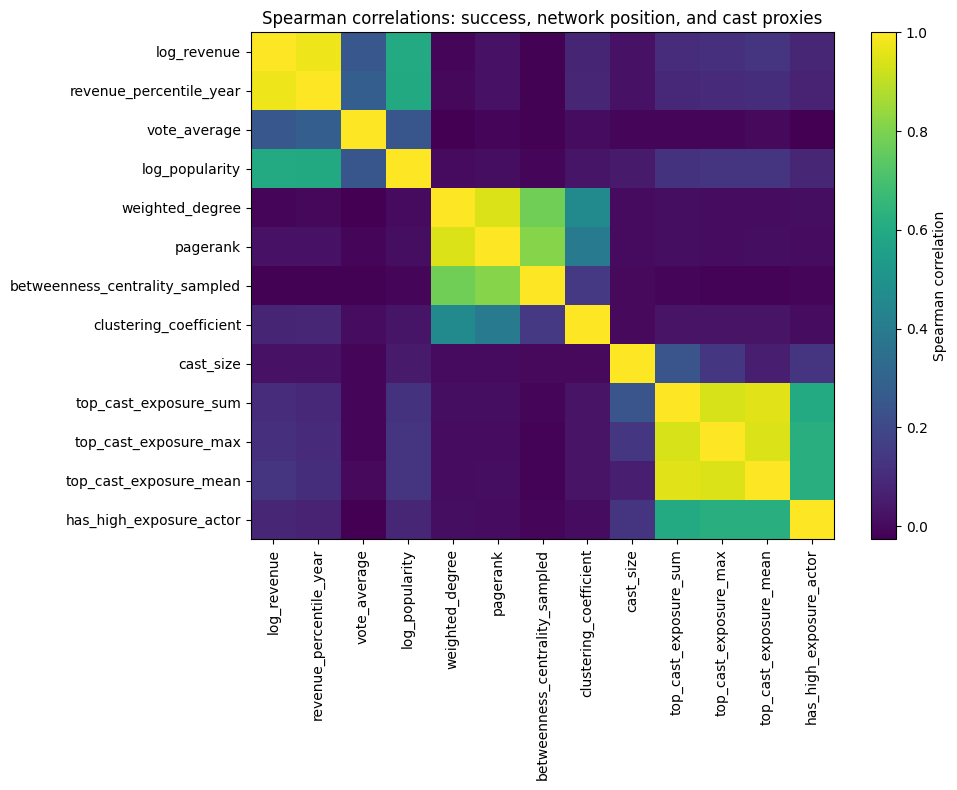

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/network_success_correlation_heatmap.png


In [10]:
plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar(label="Spearman correlation")
plt.title("Spearman correlations: success, network position, and cast proxies")
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "network_success_correlation_heatmap.png"
plt.savefig(fig_path, dpi=200)
plt.show()

print("Saved:", fig_path)

## 10. Community success summary

This is descriptive only. It compares success/outcome distributions across narrative communities.


In [11]:
community_success_summary = (
    df
    .groupby(["community_id", "suggested_label_manual"])
    .agg(
        n_films=("title", "count"),
        revenue_available_pct=("revenue_clean", lambda x: round(x.notna().mean() * 100, 2)),
        median_revenue=("revenue_clean", "median"),
        median_log_revenue=("log_revenue", "median"),
        median_revenue_percentile_year=("revenue_percentile_year", "median"),
        median_vote_average=("vote_average", "median"),
        median_vote_count=("vote_count", "median"),
        median_popularity=("popularity", "median"),
        median_weighted_degree=("weighted_degree", "median"),
        median_betweenness=("betweenness_centrality_sampled", "median"),
        median_cast_size=("cast_size", "median"),
        median_top_cast_exposure_max=("top_cast_exposure_max", "median")
    )
    .reset_index()
    .sort_values("n_films", ascending=False)
)

display(community_success_summary.head(30))

community_success_summary.to_csv(
    OUTPUT_TABLES_DIR / "community_success_summary.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "community_success_summary.csv")

,community_id,suggested_label_manual,n_films,revenue_available_pct,median_revenue,median_log_revenue,median_revenue_percentile_year,median_vote_average,median_vote_count,median_popularity,median_weighted_degree,median_betweenness,median_cast_size,median_top_cast_exposure_max
14,14,"Broad personal drama, family disruption, and domestic threat",1792,36.38,4216409.0,15.254470,0.402694,6.1000,82.0,1.52975,4.870969,0.000172,5.0,3.0
22,22,"Relationship drama, romantic comedy, and emotional-family crossover",1735,32.16,3014802.0,14.919045,0.355916,6.3000,79.0,1.27090,4.393519,0.000175,5.0,3.0
12,12,Japanese/Korean action-animation and cross-cultural personal drama,1517,34.15,7352642.0,15.810567,0.466799,6.6000,61.0,1.68390,4.047611,0.000161,5.0,4.0
2,2,"Coming-of-age, identity, and character-centered social drama",1411,41.11,7680455.5,15.854186,0.459030,6.0000,102.0,1.57790,4.501107,0.000162,5.0,3.0
24,24,"Family, personal transformation, and social drama-comedy",1327,34.97,4881639.5,15.400912,0.423798,6.1000,99.0,1.39780,4.285003,0.000163,5.0,4.0
4,4,"War, historical conflict, and political/action drama",1276,40.44,5218006.5,15.467626,0.456949,6.2790,86.5,1.47260,4.194384,0.000168,5.0,3.0
23,23,"Crime, heist, revenge, and underworld action",1031,45.68,11782282.0,16.282108,0.537815,6.1000,123.0,1.87860,4.058141,0.000159,5.0,4.0
8,8,"Survival horror, trapped-group threat, and comic ensemble adventure",1005,36.42,9120108.5,16.025978,0.493628,5.8000,100.0,1.56170,4.957902,0.000166,5.0,3.0
25,25,"Crime-thriller, mystery, and dark psychological/supernatural threat",977,33.57,6024477.0,15.611049,0.446681,6.0000,87.0,1.51200,4.472257,0.000167,5.0,3.0
10,10,"Adventure spectacle, creature threat, and family-animation peril",974,48.05,20136563.0,16.818044,0.624185,6.1000,128.5,1.89800,4.022564,0.000164,5.0,4.0


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_success_summary.csv


## 11. Regression setup

Models are estimated with OLS and HC3 robust standard errors.

The goal is not causal identification.  
The goal is to test whether network features remain associated with outcomes after simple controls.

Main controls:

- release year
- primary genre
- community label / community fixed effects in selected models
- cast exposure proxies


In [12]:
# Install if needed:
# !pip install -q statsmodels

import statsmodels.formula.api as smf

# Keep categories manageable
df_model = df.copy()

# Primary genre cleanup
df_model["primary_genre_model"] = df_model["primary_genre"].fillna("Unknown").astype(str)

# Collapse rare genres if needed
genre_counts = df_model["primary_genre_model"].value_counts()
rare_genres = genre_counts[genre_counts < 100].index
df_model.loc[df_model["primary_genre_model"].isin(rare_genres), "primary_genre_model"] = "Other"

# Community as categorical numeric string
df_model["community_id_model"] = df_model["community_id"].astype(str)

# Year centered for numerical stability
df_model["release_year_centered"] = df_model["release_year"] - df_model["release_year"].median()

print("df_model:", df_model.shape)
print("Genres used:", df_model["primary_genre_model"].nunique())
print("Communities used:", df_model["community_id_model"].nunique())

df_model: (19202, 61)
Genres used: 17
Communities used: 26


In [13]:
def fit_ols_formula(data, formula, outcome_name, model_name, min_rows=200):
    model_data = data.copy()
    yvar = formula.split("~")[0].strip()
    model_data = model_data[model_data[yvar].notna()].copy()

    if len(model_data) < min_rows:
        raise ValueError(f"Too few rows for {model_name}: {len(model_data)}")

    fit = smf.ols(formula=formula, data=model_data).fit(cov_type="HC3")

    params = fit.params
    conf = fit.conf_int()
    pvals = fit.pvalues

    results = pd.DataFrame({
        "outcome": outcome_name,
        "model": model_name,
        "term": params.index,
        "coef": params.values,
        "ci_low": conf[0].values,
        "ci_high": conf[1].values,
        "p_value": pvals.values,
        "n_obs": int(fit.nobs),
        "r_squared": fit.rsquared,
        "adj_r_squared": fit.rsquared_adj
    })

    return fit, results

print("Regression helper ready.")

Regression helper ready.


## 12. Regression models: log revenue

Subset: films with positive revenue data.

Models:

1. Network features + year + genre
2. Add cast/star exposure proxies
3. Add community fixed effects


In [14]:
network_terms = (
    "z_weighted_degree + z_pagerank + "
    "z_betweenness_centrality_sampled + z_clustering_coefficient"
)

cast_terms = (
    "z_cast_size + z_top_cast_exposure_max + has_high_exposure_actor"
)

controls = "release_year_centered + C(primary_genre_model)"
community_controls = "C(community_id_model)"

formulas_log_revenue = {
    "M1_network_genre_year": f"log_revenue ~ {network_terms} + {controls}",
    "M2_add_cast_proxy": f"log_revenue ~ {network_terms} + {cast_terms} + {controls}",
    "M3_add_community_FE": f"log_revenue ~ {network_terms} + {cast_terms} + {controls} + {community_controls}",
}

log_revenue_results_list = []
log_revenue_fits = {}

for name, formula in formulas_log_revenue.items():
    fit, res = fit_ols_formula(
        df_model,
        formula,
        outcome_name="log_revenue",
        model_name=name
    )
    log_revenue_fits[name] = fit
    log_revenue_results_list.append(res)
    print(name, "n=", int(fit.nobs), "R2=", round(fit.rsquared, 4))

log_revenue_results = pd.concat(log_revenue_results_list, ignore_index=True)
display(log_revenue_results.head(30))

log_revenue_results.to_csv(
    OUTPUT_TABLES_DIR / "regression_results_log_revenue.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "regression_results_log_revenue.csv")

M1_network_genre_year n= 7576 R2= 0.1008
M2_add_cast_proxy n= 7576 R2= 0.1092
M3_add_community_FE n= 7576 R2= 0.133


,outcome,model,term,coef,ci_low,ci_high,p_value,n_obs,r_squared,adj_r_squared
0,log_revenue,M1_network_genre_year,Intercept,16.359742,16.191353,16.528132,0.000000e+00,7576,0.100796,0.098297
1,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Adventure],0.538589,0.224270,0.852908,7.839047e-04,7576,0.100796,0.098297
2,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Animation],0.031069,-0.260494,0.322631,8.345628e-01,7576,0.100796,0.098297
3,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Comedy],-1.006751,-1.212497,-0.801005,8.770547e-22,7576,0.100796,0.098297
4,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Crime],-1.241868,-1.617342,-0.866394,9.020928e-11,7576,0.100796,0.098297
5,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Drama],-1.751189,-1.959678,-1.542700,6.812414e-61,7576,0.100796,0.098297
6,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Family],0.289956,-0.054736,0.634649,9.920377e-02,7576,0.100796,0.098297
7,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Fantasy],-0.122934,-0.591913,0.346045,6.074154e-01,7576,0.100796,0.098297
8,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.History],-1.418734,-2.155455,-0.682013,1.604028e-04,7576,0.100796,0.098297
9,log_revenue,M1_network_genre_year,C(primary_genre_model)[T.Horror],-1.289005,-1.590708,-0.987302,5.578711e-17,7576,0.100796,0.098297


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_log_revenue.csv


## 13. Regression models: revenue percentile within release year

This outcome is safer than raw revenue for cross-decade comparison because it compares films within their release year.


In [15]:
formulas_revenue_pct = {
    "M1_network_genre_year": f"revenue_percentile_year ~ {network_terms} + {controls}",
    "M2_add_cast_proxy": f"revenue_percentile_year ~ {network_terms} + {cast_terms} + {controls}",
    "M3_add_community_FE": f"revenue_percentile_year ~ {network_terms} + {cast_terms} + {controls} + {community_controls}",
}

revenue_pct_results_list = []
revenue_pct_fits = {}

for name, formula in formulas_revenue_pct.items():
    fit, res = fit_ols_formula(
        df_model,
        formula,
        outcome_name="revenue_percentile_year",
        model_name=name
    )
    revenue_pct_fits[name] = fit
    revenue_pct_results_list.append(res)
    print(name, "n=", int(fit.nobs), "R2=", round(fit.rsquared, 4))

revenue_pct_results = pd.concat(revenue_pct_results_list, ignore_index=True)
display(revenue_pct_results.head(30))

revenue_pct_results.to_csv(
    OUTPUT_TABLES_DIR / "regression_results_revenue_percentile.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "regression_results_revenue_percentile.csv")

M1_network_genre_year n= 7576 R2= 0.0962
M2_add_cast_proxy n= 7576 R2= 0.1053
M3_add_community_FE n= 7576 R2= 0.1308


,outcome,model,term,coef,ci_low,ci_high,p_value,n_obs,r_squared,adj_r_squared
0,revenue_percentile_year,M1_network_genre_year,Intercept,0.597062,0.579542,0.614582,0.000000e+00,7576,0.096207,0.093695
1,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Adventure],0.057663,0.024528,0.090798,6.477393e-04,7576,0.096207,0.093695
2,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Animation],-0.002164,-0.034205,0.029878,8.947041e-01,7576,0.096207,0.093695
3,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Comedy],-0.115027,-0.136515,-0.093540,9.382012e-26,7576,0.096207,0.093695
4,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Crime],-0.123943,-0.160835,-0.087052,4.552604e-11,7576,0.096207,0.093695
5,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Drama],-0.191572,-0.212699,-0.170444,1.171528e-70,7576,0.096207,0.093695
6,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Family],0.039194,0.000316,0.078073,4.816895e-02,7576,0.096207,0.093695
7,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Fantasy],-0.001916,-0.048881,0.045049,9.362615e-01,7576,0.096207,0.093695
8,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.History],-0.159499,-0.227906,-0.091093,4.878830e-06,7576,0.096207,0.093695
9,revenue_percentile_year,M1_network_genre_year,C(primary_genre_model)[T.Horror],-0.140746,-0.171960,-0.109533,9.758349e-19,7576,0.096207,0.093695


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_revenue_percentile.csv


## 14. Regression models: vote average

This is a rating/quality-perception proxy, not commercial success.


In [16]:
formulas_vote_average = {
    "M1_network_genre_year": f"vote_average ~ {network_terms} + {controls}",
    "M2_add_cast_proxy": f"vote_average ~ {network_terms} + {cast_terms} + {controls}",
    "M3_add_community_FE": f"vote_average ~ {network_terms} + {cast_terms} + {controls} + {community_controls}",
}

vote_average_results_list = []
vote_average_fits = {}

for name, formula in formulas_vote_average.items():
    fit, res = fit_ols_formula(
        df_model,
        formula,
        outcome_name="vote_average",
        model_name=name
    )
    vote_average_fits[name] = fit
    vote_average_results_list.append(res)
    print(name, "n=", int(fit.nobs), "R2=", round(fit.rsquared, 4))

vote_average_results = pd.concat(vote_average_results_list, ignore_index=True)
display(vote_average_results.head(30))

vote_average_results.to_csv(
    OUTPUT_TABLES_DIR / "regression_results_vote_average.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "regression_results_vote_average.csv")

M1_network_genre_year n= 19202 R2= 0.1526
M2_add_cast_proxy n= 19202 R2= 0.1535
M3_add_community_FE n= 19202 R2= 0.184


,outcome,model,term,coef,ci_low,ci_high,p_value,n_obs,r_squared,adj_r_squared
0,vote_average,M1_network_genre_year,Intercept,6.019950,5.978760,6.061141,0.000000e+00,19202,0.152551,0.151623
1,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Adventure],0.287474,0.200152,0.374796,1.100639e-10,19202,0.152551,0.151623
2,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Animation],0.881563,0.812075,0.951051,1.772342e-136,19202,0.152551,0.151623
3,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Comedy],-0.052385,-0.101083,-0.003687,3.499909e-02,19202,0.152551,0.151623
4,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Crime],0.247298,0.172961,0.321634,7.017713e-11,19202,0.152551,0.151623
5,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Drama],0.397691,0.351183,0.444199,4.815236e-63,19202,0.152551,0.151623
6,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Family],0.298353,0.206590,0.390115,1.859308e-10,19202,0.152551,0.151623
7,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Fantasy],0.074809,-0.039853,0.189472,2.009884e-01,19202,0.152551,0.151623
8,vote_average,M1_network_genre_year,C(primary_genre_model)[T.History],0.495944,0.360898,0.630990,6.119847e-13,19202,0.152551,0.151623
9,vote_average,M1_network_genre_year,C(primary_genre_model)[T.Horror],-0.696056,-0.755815,-0.636297,2.352472e-115,19202,0.152551,0.151623


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_vote_average.csv


## 15. Regression models: log popularity

This is a platform attention proxy. Interpret cautiously.


In [17]:
formulas_popularity = {
    "M1_network_genre_year": f"log_popularity ~ {network_terms} + {controls}",
    "M2_add_cast_proxy": f"log_popularity ~ {network_terms} + {cast_terms} + {controls}",
    "M3_add_community_FE": f"log_popularity ~ {network_terms} + {cast_terms} + {controls} + {community_controls}",
}

popularity_results_list = []
popularity_fits = {}

for name, formula in formulas_popularity.items():
    fit, res = fit_ols_formula(
        df_model,
        formula,
        outcome_name="log_popularity",
        model_name=name
    )
    popularity_fits[name] = fit
    popularity_results_list.append(res)
    print(name, "n=", int(fit.nobs), "R2=", round(fit.rsquared, 4))

popularity_results = pd.concat(popularity_results_list, ignore_index=True)
display(popularity_results.head(30))

popularity_results.to_csv(
    OUTPUT_TABLES_DIR / "regression_results_popularity.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "regression_results_popularity.csv")

M1_network_genre_year n= 19202 R2= 0.0567
M2_add_cast_proxy n= 19202 R2= 0.069
M3_add_community_FE n= 19202 R2= 0.0799


,outcome,model,term,coef,ci_low,ci_high,p_value,n_obs,r_squared,adj_r_squared
0,log_popularity,M1_network_genre_year,Intercept,1.267830,1.242441,1.293219,0.000000e+00,19202,0.056739,0.055707
1,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Adventure],0.033215,-0.027813,0.094244,2.860950e-01,19202,0.056739,0.055707
2,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Animation],0.025976,-0.023365,0.075318,3.021389e-01,19202,0.056739,0.055707
3,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Comedy],-0.320709,-0.350345,-0.291072,7.839551e-100,19202,0.056739,0.055707
4,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Crime],-0.181668,-0.226821,-0.136516,3.125603e-15,19202,0.056739,0.055707
5,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Drama],-0.280562,-0.309499,-0.251626,1.590158e-80,19202,0.056739,0.055707
6,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Family],-0.169760,-0.231529,-0.107991,7.181671e-08,19202,0.056739,0.055707
7,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Fantasy],-0.017420,-0.083788,0.048948,6.069433e-01,19202,0.056739,0.055707
8,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.History],-0.267780,-0.350470,-0.185090,2.194797e-10,19202,0.056739,0.055707
9,log_popularity,M1_network_genre_year,C(primary_genre_model)[T.Horror],-0.307569,-0.342438,-0.272700,5.765636e-67,19202,0.056739,0.055707


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_popularity.csv


## 16. Compact coefficient summary for thesis

This extracts only the main network and cast-proxy terms from all models.


In [18]:
all_reg_results = pd.concat(
    [
        log_revenue_results,
        revenue_pct_results,
        vote_average_results,
        popularity_results
    ],
    ignore_index=True
)

terms_of_interest = [
    "z_weighted_degree",
    "z_pagerank",
    "z_betweenness_centrality_sampled",
    "z_clustering_coefficient",
    "z_cast_size",
    "z_top_cast_exposure_max",
    "has_high_exposure_actor"
]

coef_summary = all_reg_results[
    all_reg_results["term"].isin(terms_of_interest)
].copy()

coef_summary["significant_05"] = coef_summary["p_value"] < 0.05
coef_summary["coef_rounded"] = coef_summary["coef"].round(4)
coef_summary["p_value_rounded"] = coef_summary["p_value"].round(4)

display(coef_summary)

coef_summary.to_csv(
    OUTPUT_TABLES_DIR / "regression_key_coefficients_summary.csv",
    index=False
)

print("Saved:", OUTPUT_TABLES_DIR / "regression_key_coefficients_summary.csv")

,outcome,model,term,coef,ci_low,ci_high,p_value,n_obs,r_squared,adj_r_squared,significant_05,coef_rounded,p_value_rounded
17,log_revenue,M1_network_genre_year,z_weighted_degree,-0.740403,-0.921414,-0.559392,1.083710e-15,7576,0.100796,0.098297,True,-0.7404,0.0000
18,log_revenue,M1_network_genre_year,z_pagerank,0.780574,0.597516,0.963632,6.408660e-17,7576,0.100796,0.098297,True,0.7806,0.0000
19,log_revenue,M1_network_genre_year,z_betweenness_centrality_sampled,-0.190242,-0.281647,-0.098837,4.517626e-05,7576,0.100796,0.098297,True,-0.1902,0.0000
20,log_revenue,M1_network_genre_year,z_clustering_coefficient,0.185379,0.116397,0.254361,1.385894e-07,7576,0.100796,0.098297,True,0.1854,0.0000
39,log_revenue,M2_add_cast_proxy,z_weighted_degree,-0.724853,-0.905166,-0.544540,3.299939e-15,7576,0.109226,0.106395,True,-0.7249,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
382,log_popularity,M3_add_community_FE,z_betweenness_centrality_sampled,-0.016944,-0.028440,-0.005449,3.865569e-03,19202,0.079918,0.077564,True,-0.0169,0.0039
383,log_popularity,M3_add_community_FE,z_clustering_coefficient,0.019109,0.009774,0.028444,6.020504e-05,19202,0.079918,0.077564,True,0.0191,0.0001
384,log_popularity,M3_add_community_FE,z_cast_size,0.036083,0.026834,0.045332,2.063500e-14,19202,0.079918,0.077564,True,0.0361,0.0000
385,log_popularity,M3_add_community_FE,z_top_cast_exposure_max,0.034647,0.025638,0.043657,4.786618e-14,19202,0.079918,0.077564,True,0.0346,0.0000


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_key_coefficients_summary.csv


## 17. Diagnostic plots

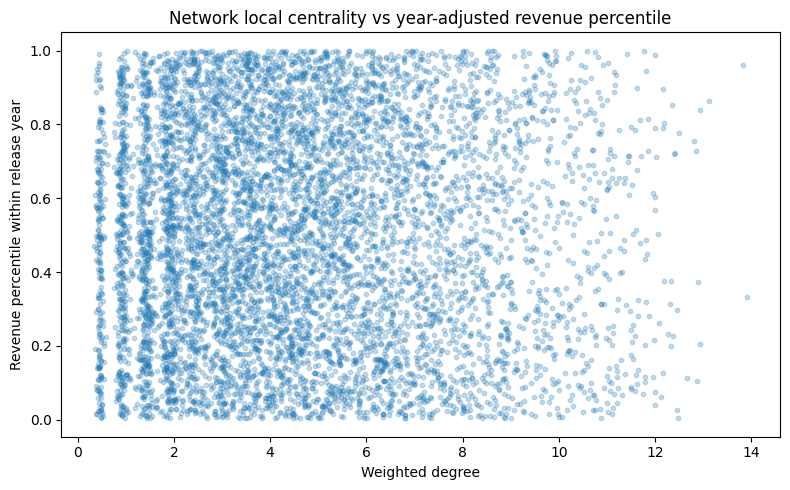

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/weighted_degree_vs_revenue_percentile.png


In [19]:
# Weighted degree vs revenue percentile
plot_df = df_model[
    df_model["revenue_percentile_year"].notna() &
    df_model["weighted_degree"].notna()
].copy()

plt.figure(figsize=(8, 5))
plt.scatter(
    plot_df["weighted_degree"],
    plot_df["revenue_percentile_year"],
    alpha=0.25,
    s=10
)
plt.xlabel("Weighted degree")
plt.ylabel("Revenue percentile within release year")
plt.title("Network local centrality vs year-adjusted revenue percentile")
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "weighted_degree_vs_revenue_percentile.png"
plt.savefig(fig_path, dpi=200)
plt.show()

print("Saved:", fig_path)

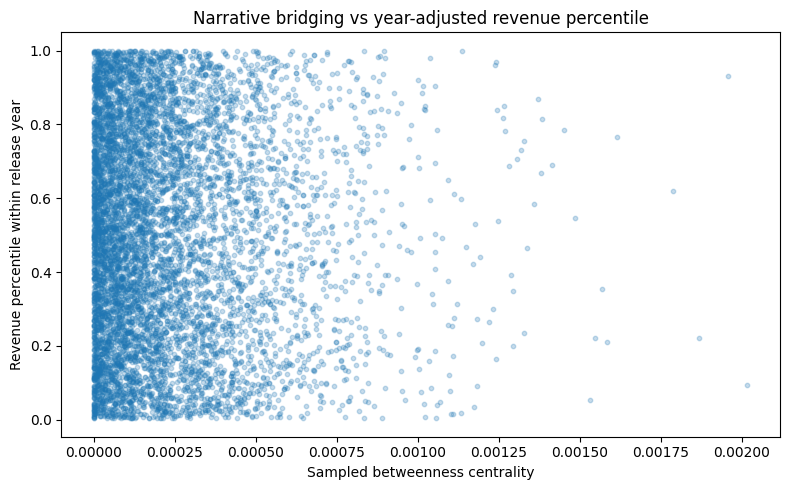

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/figures/betweenness_vs_revenue_percentile.png


In [20]:
# Betweenness vs revenue percentile
plot_df = df_model[
    df_model["revenue_percentile_year"].notna() &
    df_model["betweenness_centrality_sampled"].notna()
].copy()

plt.figure(figsize=(8, 5))
plt.scatter(
    plot_df["betweenness_centrality_sampled"],
    plot_df["revenue_percentile_year"],
    alpha=0.25,
    s=10
)
plt.xlabel("Sampled betweenness centrality")
plt.ylabel("Revenue percentile within release year")
plt.title("Narrative bridging vs year-adjusted revenue percentile")
plt.tight_layout()

fig_path = OUTPUT_FIGURES_DIR / "betweenness_vs_revenue_percentile.png"
plt.savefig(fig_path, dpi=200)
plt.show()

print("Saved:", fig_path)

## 18. Save final modeling table

In [21]:
# Drop list columns before CSV export
export_df = df_model.copy()

for col in ["cast_list", "top_cast_list"]:
    if col in export_df.columns:
        export_df[col] = export_df[col].apply(lambda x: "; ".join(x) if isinstance(x, list) else x)

export_df.to_csv(MODELING_TABLE_OUT, index=False, encoding="utf-8")

print("Saved modeling table:", MODELING_TABLE_OUT)
print("Shape:", export_df.shape)

Saved modeling table: /content/drive/MyDrive/thesis_movie_project/processed/features/modeling_table_success_star_power.csv
Shape: (19202, 61)


## 19. Thesis interpretation notes

These notes summarize how to write this section.


In [22]:
notes = f'''
Success and star-power analysis notes

The modeling table contains {len(df_model):,} films from the semantic network largest connected component.
Revenue is available for {df_model["revenue_clean"].notna().sum():,} films, so commercial-success models are estimated on a revenue-available subset.
To reduce cross-decade comparability problems, revenue is analyzed both as log revenue and as a percentile within release year.

Network features include weighted degree, PageRank, sampled betweenness centrality, and clustering coefficient.
These features describe narrative position in the semantic similarity network, not fame or quality.

Star power is proxied using cast-list information:
- cast size;
- top-cast exposure based on repeated appearance of actors in the network dataset;
- presence of a high-exposure actor.

These are practical metadata-based proxies, not perfect measures of historical star power.
Results should be interpreted as associations, not causal effects.
'''.strip()

notes_path = OUTPUT_TABLES_DIR / "success_star_power_notes.txt"
notes_path.write_text(notes, encoding="utf-8")

print(notes)
print("\nSaved:", notes_path)

Success and star-power analysis notes

The modeling table contains 19,202 films from the semantic network largest connected component.
Revenue is available for 7,576 films, so commercial-success models are estimated on a revenue-available subset.
To reduce cross-decade comparability problems, revenue is analyzed both as log revenue and as a percentile within release year.

Network features include weighted degree, PageRank, sampled betweenness centrality, and clustering coefficient.
These features describe narrative position in the semantic similarity network, not fame or quality.

Star power is proxied using cast-list information:
- cast size;
- top-cast exposure based on repeated appearance of actors in the network dataset;
- presence of a high-exposure actor.

These are practical metadata-based proxies, not perfect measures of historical star power.
Results should be interpreted as associations, not causal effects.

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/tables/s

## 20. Final output list

In [23]:
outputs = [
    MODELING_TABLE_OUT,
    OUTPUT_TABLES_DIR / "actor_exposure_counts.csv",
    OUTPUT_TABLES_DIR / "modeling_sample_audit.csv",
    OUTPUT_TABLES_DIR / "network_success_correlations.csv",
    OUTPUT_TABLES_DIR / "community_success_summary.csv",
    OUTPUT_TABLES_DIR / "regression_results_log_revenue.csv",
    OUTPUT_TABLES_DIR / "regression_results_revenue_percentile.csv",
    OUTPUT_TABLES_DIR / "regression_results_vote_average.csv",
    OUTPUT_TABLES_DIR / "regression_results_popularity.csv",
    OUTPUT_TABLES_DIR / "regression_key_coefficients_summary.csv",
    OUTPUT_TABLES_DIR / "success_star_power_notes.txt",
    OUTPUT_FIGURES_DIR / "network_success_correlation_heatmap.png",
    OUTPUT_FIGURES_DIR / "weighted_degree_vs_revenue_percentile.png",
    OUTPUT_FIGURES_DIR / "betweenness_vs_revenue_percentile.png",
]

print("Created/expected outputs:")
for p in outputs:
    print(p.exists(), "-", p)

Created/expected outputs:
True - /content/drive/MyDrive/thesis_movie_project/processed/features/modeling_table_success_star_power.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/actor_exposure_counts.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/modeling_sample_audit.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_success_correlations.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_success_summary.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_log_revenue.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_revenue_percentile.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_vote_average.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression_results_popularity.csv
True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/regression

## 21. What comes next

After this notebook, the next step is:

`06_robustness_checks.ipynb`

Possible robustness checks:

1. Compare results with and without community fixed effects.
2. Compare revenue percentile vs log revenue outcomes.
3. Use alternative success thresholds.
4. Check whether results are driven by specific large communities.
5. Check whether high-star-power films behave differently from low-star-power films.
